In [1]:
import pandas as pd
import numpy as np

from pathlib import Path
cwd = Path.cwd()

In [16]:
model_number = 3
trial_number = 2

trial_dir = f"model_v{model_number}_test_{trial_number}"

DATA_DIR = cwd.parent / "test" / trial_dir / "test.csv"

In [17]:
df = pd.read_csv(DATA_DIR, low_memory=False)
df.head(5)

,epoch,bg_rmse,bg_mae,bg_r2,fe_rmse,fe_mae,fe_r2
0,1,1.048345,0.825841,0.172461,1.095720,0.885262,-0.409669
1,2,0.869881,0.699656,0.430231,0.834573,0.674964,0.182201
2,3,0.823946,0.654403,0.488817,0.692816,0.553195,0.436422
3,4,0.908081,0.726362,0.379090,0.669752,0.537796,0.473320
4,5,0.777751,0.617081,0.544529,0.525362,0.426282,0.675932


In [18]:
import matplotlib.pyplot as plt

In [19]:
def graph_metric(metric):    
    metric = metric.lower() # Ensure it matches 'mae', 'rmse', or 'r2'
    col_bg = f"bg_{metric}"
    col_fe = f"fe_{metric}"
    
    # 2. Setup the side-by-side figure
    plt.figure(figsize=(14, 5))
    
    # --- Left: Band Gap Graph ---
    plt.subplot(1, 2, 1)
    plt.plot(df['epoch'], df[col_bg], label=f'Test {metric.upper()}', color='royalblue', linewidth=2)
    plt.title(f'Band Gap Performance ({metric.upper()})', fontsize=14)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel(metric.upper(), fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend()

    # --- Right: Formation Energy Graph ---
    plt.subplot(1, 2, 2)
    plt.plot(df['epoch'], df[col_fe], label=f'Test {metric.upper()}', color='forestgreen', linewidth=2)
    plt.title(f'Formation Energy Performance ({metric.upper()})', fontsize=14)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel(metric.upper(), fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend()

    plt.tight_layout()
    plt.show()

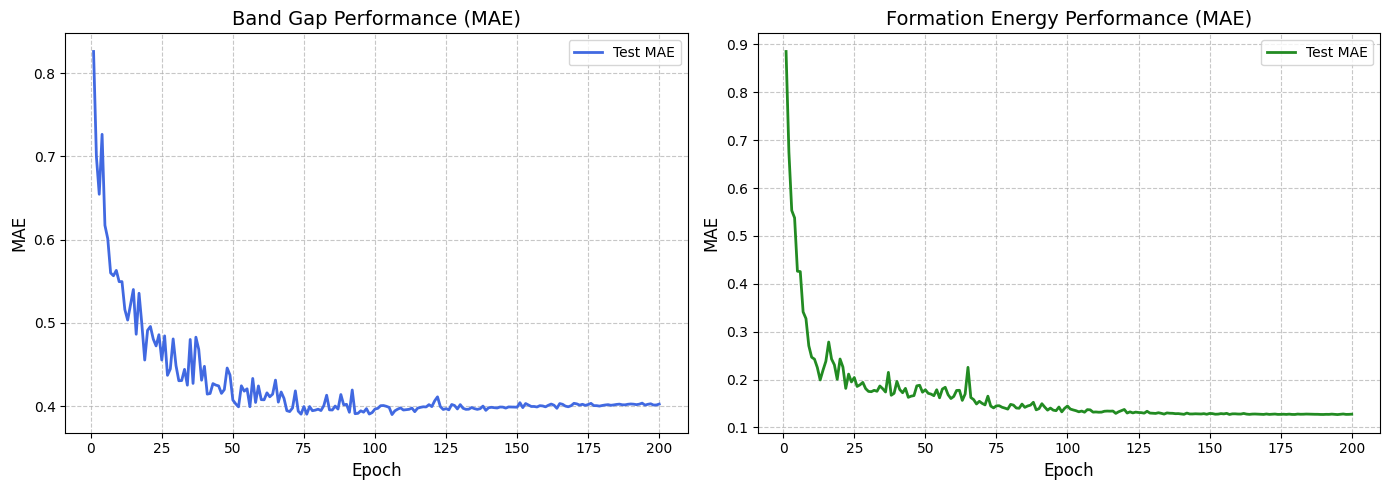

In [20]:
graph_metric('mae')

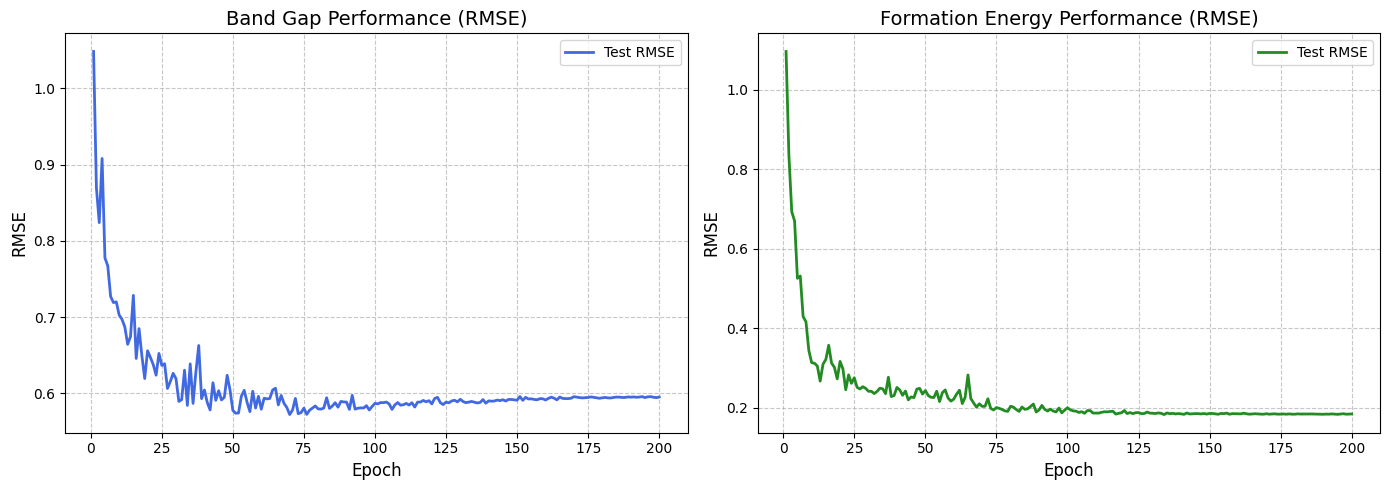

In [21]:
graph_metric('rmse')

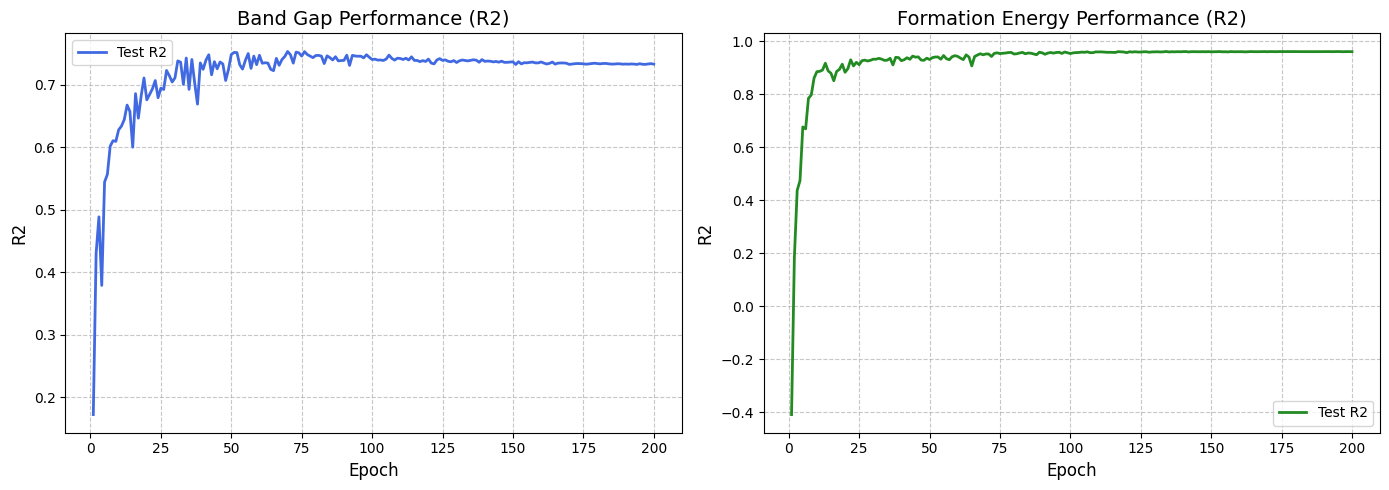

In [22]:
graph_metric('r2')